# 제12교시. VLM: 이미지 벡터는 어떻게 언어 모델에 들어갈까요?


## 이번 교시의 목표

- 그림과 질문이 각각 어떻게 처리되고, 어디에서 한 입력으로 합쳐지는지 설명합니다.
- 패치 1,024개가 이미지 자리 64개로 바뀌는 과정을 텐서의 모양과 값으로 확인합니다.
- 그림이 전달됐다는 검사와 답변이 그림에 맞는다는 판단을 구분합니다.


## 이번 교시 핵심 용어

- **비전 언어 모델(vision-language model, VLM):** 시각 입력과 언어 입력을 함께 처리하는 모델입니다.
- **비전 인코더(vision encoder):** 이미지 패치마다 특징 벡터를 만듭니다.
- **연결부(connector):** 시각 벡터를 묶고 언어 모델이 받을 폭으로 바꿉니다.
- **픽셀 셔플(pixel shuffle):** 이 실습에서는 원본 픽셀이 아니라 이웃한 시각 벡터의 성분을 재배열합니다.
- **이미지 자리표시자(image placeholder):** 언어 입력에서 이미지 벡터가 들어갈 위치를 표시하는 특수 토큰입니다.


## 실습 준비

- VS Code에서 이 파일을 열고 1교시에서 만든 프로젝트의 Python 3.12 커널을 선택합니다. PyTorch 2.9.1(CUDA 12.6 빌드), Transformers 5.23.0을 사용합니다. 11교시에서 모델을 실행한 커널은 종료하고 새 커널에서 시작합니다.
- 공개 모델의 첫 실행에는 약 513 MB의 가중치를 다운로드합니다. 같은 revision은 로컬 캐시를 재사용합니다. 로그인·API 키·별도 이미지 파일은 필요하지 않습니다.
- 위에서부터 순서대로 실행합니다. 환경 검사나 `assert`에서 멈추면 문제를 먼저 해결하고 이어서 실행합니다. 모델 또는 패키지 버전을 임의로 바꾸지 않습니다.
- `OUT`이 가리키는 `results/`의 JSON과 원본 그림, 실행 출력이 남은 이 노트북을 보관합니다.


## 전체 흐름 먼저 보기

11교시 ViT에서는 패치 벡터를 처리한 뒤 최종 CLS 벡터로 분류 점수를 구했습니다. 이번 SmolVLM에서도 출발점은 패치 벡터입니다. 하지만 분류 이름을 고르는 대신 여러 시각 벡터를 언어 모델에 넣어 **그림을 참고해 질문에 답하는 문장**을 생성하는 경로를 봅니다.

1. **그림 경로:** 비전 인코더가 픽셀을 읽어 시각 벡터 1,024개를 만듭니다. 연결부는 이를 묶고 투영해 폭 576의 시각 벡터 64개를 만듭니다.
2. **질문 경로:** 질문에 채팅 형식을 적용해 토큰 ID로 바꿉니다. 이 입력의 85개 ID 중 64개가 이미지 자리표시자입니다. 사진의 내용은 이 ID에 들어 있지 않습니다.
3. **합류:** ID를 임베딩으로 바꾼 뒤 이미지 자리의 벡터만 시각 벡터로 교체합니다. 질문과 역할·경계 표식 등 나머지 벡터는 그대로 둡니다. 언어 모델은 이 혼합 벡터열을 받아 다음 토큰을 계산합니다.

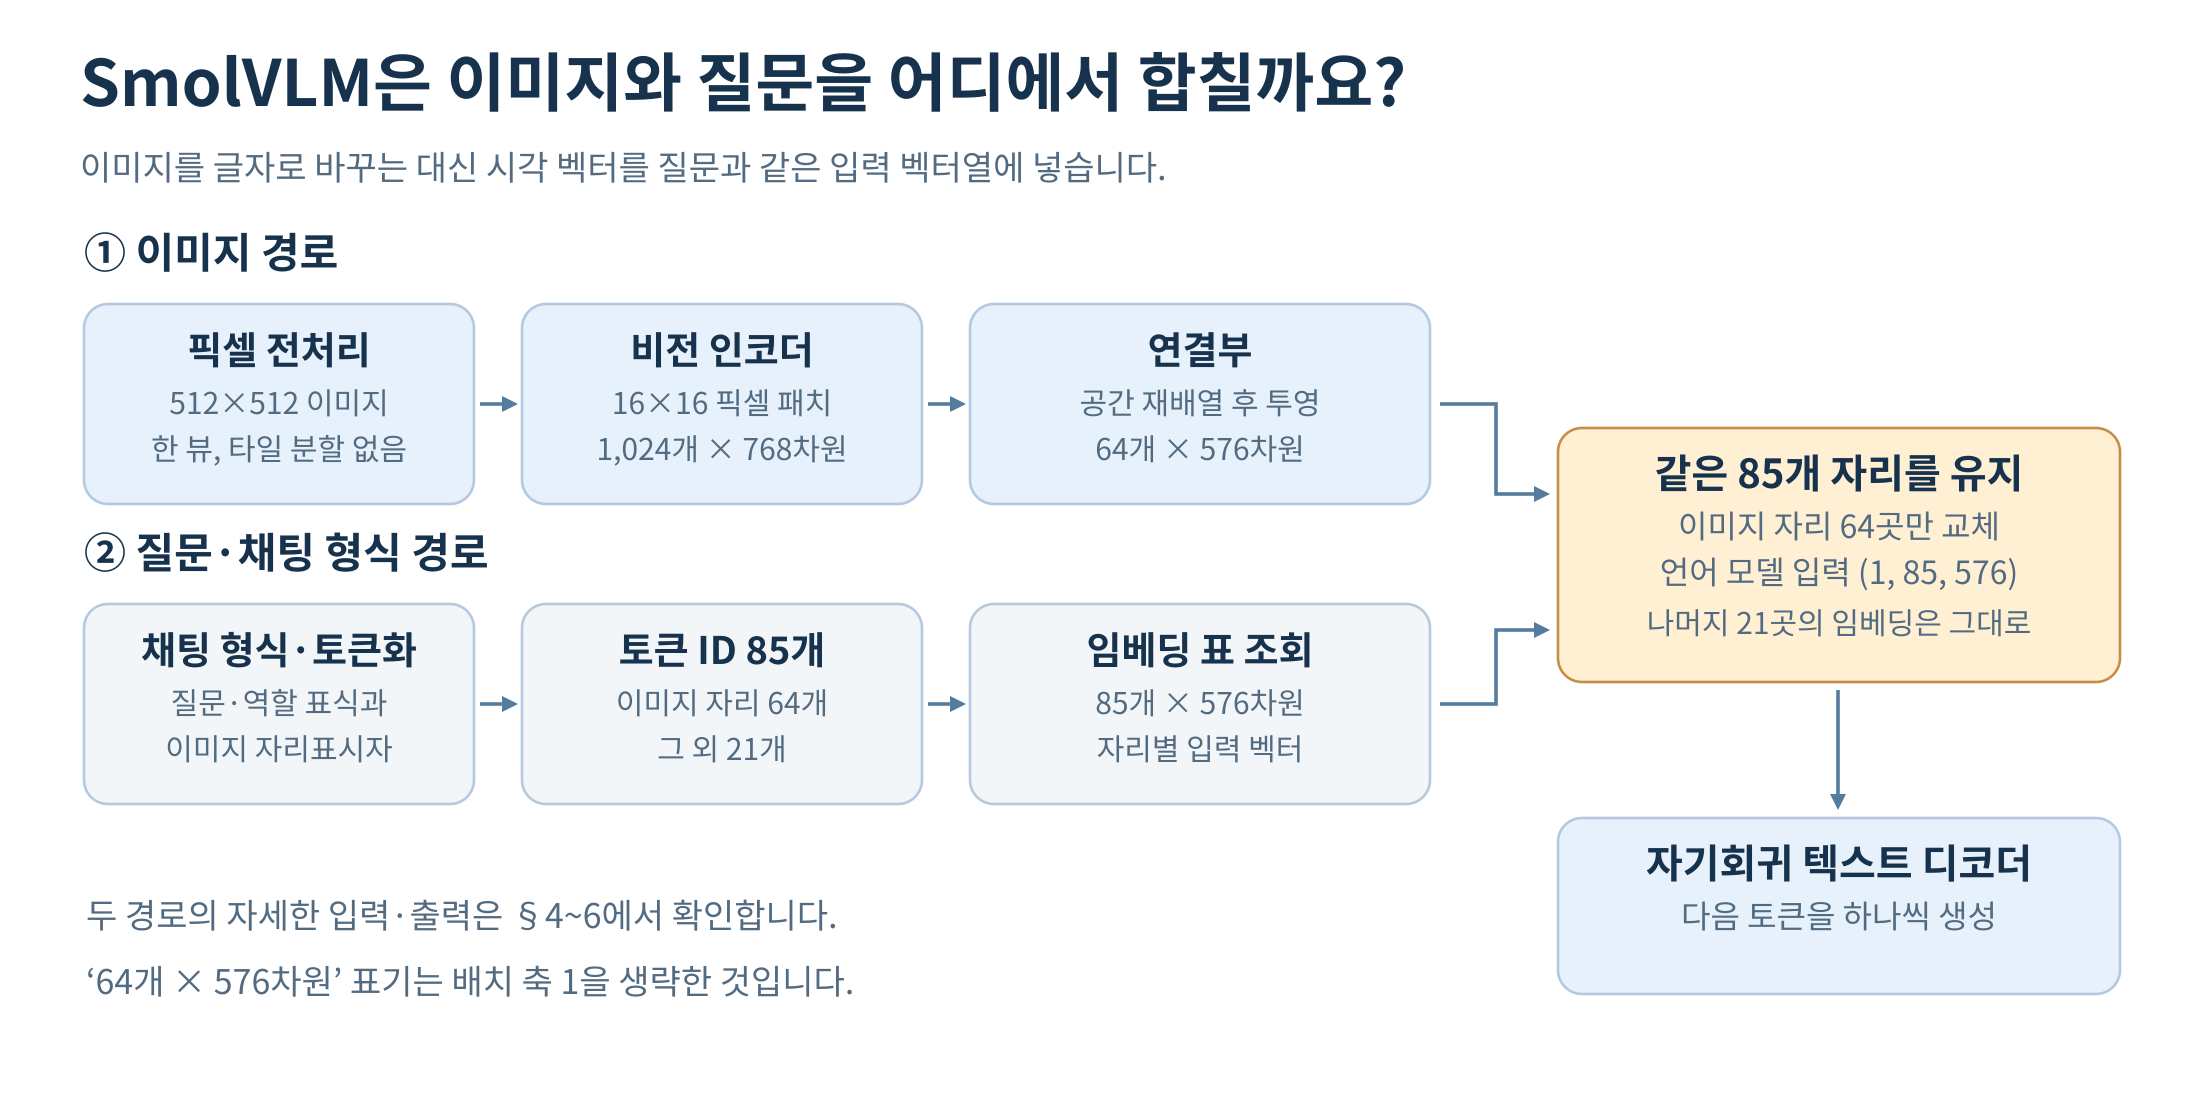

**그림 설명:** 이미지를 글자로 바꾸지 않습니다. 질문과 채팅 형식으로 정한 85개 자리 가운데 64곳에 시각 벡터를 넣고, 그 벡터열을 언어 모델에 넘깁니다.


### 참고: 다른 VLM은 위치 정보를 어디에 넣을까요?

이미지 패치는 문장 토큰과 달리 행·열이 있습니다. [Qwen3-VL 기술 보고서 §2](https://arxiv.org/html/2511.21631#S2)의 예에서는 비전 인코더가 절대 위치 임베딩과 2D RoPE로 패치 위치를 다루고, 언어 모델은 시간·높이·너비를 구별하는 교차 배치형 멀티모달 RoPE(Interleaved MRoPE)를 사용합니다. 이는 다른 모델의 설계 예로, 아래 SmolVLM 실습에서 확인하는 기능은 아닙니다.


## 1. 실행 환경 확인


### 코드 설명: 장치와 버전 확인하기

이 셀은 현재 커널의 PyTorch·Transformers 버전과 계산 장치를 표시합니다. 환경 PASS는 실행 준비를 확인한 것이며 모델 로드나 이미지 전달을 검사한 결과는 아닙니다.


In [1]:
# 생성문뿐 아니라 이미지 특징이 언어 입력에 들어가는 실제 경로를 관찰합니다.
import sys, platform, json, gc, time
from pathlib import Path
import numpy as np
import torch, transformers
from PIL import Image, ImageDraw
assert platform.system() == "Windows", "이 실습은 Windows 11 x64용입니다."
assert sys.version_info[:2] == (3, 12), "프로젝트 Python 3.12 커널을 선택하세요."
assert torch.__version__.split("+")[0] == "2.9.1", "수업 기준 PyTorch 버전을 확인하세요."
assert torch.version.cuda == "12.6", "수업 기준 cu126 설치를 확인하세요."
assert transformers.__version__ == "5.23.0", "수업 기준 Transformers 버전을 확인하세요."
assert torch.cuda.is_available(), "CUDA 사용 불가: CPU 실행은 PASS가 아닙니다."
# 난수 조건을 고정하되 이번 실습은 optimizer나 가중치 갱신 없이 추론 경로만 관찰합니다.
torch.manual_seed(42)
# 모델과 입력의 계산 장치를 공유합니다. 관찰한 텐서는 뒤에서 CPU로 복사해 비교합니다.
DEVICE = "cuda"
# 실수 입력과 가중치는 같은 자료형을 쓰되 토큰 ID는 정수로 유지합니다.
DTYPE = torch.float32
print("[PASS] environment", torch.__version__, transformers.__version__, torch.cuda.get_device_name(0))

%USERPROFILE%\AI-Engineering\python31210-signed-qa-20261117\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[PASS] environment 2.9.1+cu126 5.23.0 NVIDIA GeForce RTX 4090


### 출력 설명

저장된 출력은 PyTorch 2.9.1+cu126·Transformers 5.23.0, RTX 4090에서 실행한 기록입니다. 이 장치에서 통과한 기록을 다른 GPU의 속도나 메모리 충분함에 대한 보장으로 읽지 않습니다.

환경 PASS는 모델 앞단의 실행 조건 확인입니다. 실제 SmolVLM 가중치 로드, 시각 벡터의 연결, 생성 결과는 각각 다른 뒤의 셀에서 확인하므로 이 단계의 성공으로 이미지 이해까지 판단하지 않습니다.

IProgress 경고는 진행 막대용 위젯을 찾지 못했다는 안내입니다. 이 기록은 이후 PASS까지 진행했으므로 가중치나 CUDA 계산 실패의 증거가 아닙니다.


## 2. 나중에 답변과 대조할 그림 만들기

### 개념 먼저

11교시와 같은 도형 예제를 코드로 그립니다. 흰 바탕에 **빨간 사각형 한 개와 파란 원 한 개**입니다. 답변이 나오면 사람이 색·모양·개수를 직접 대조할 수 있습니다. 저장과 모델 입력에는 512×512 원본을 사용하고, 화면에는 축소한 256×256 사본을 표시합니다.


### 코드 설명: 원본과 표시용 그림 구분하기

Pillow의 `Image.new`와 `ImageDraw`로 RGB 도형을 만들고 `image.save`로 원본을 보관합니다. `display(image.resize(...))`는 화면에 보이는 사본만 줄입니다. §4의 입력 처리기에는 변수 `image`에 남은 원본을 넘깁니다.


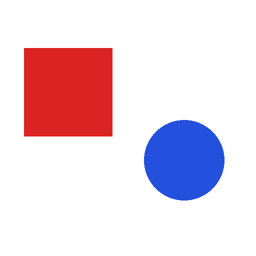

[PASS] local RGB fixture (512, 512)


In [2]:
# 외부 사진을 받지 않고 학습용 기하 도형을 직접 만듭니다.
# 실제 그림과 생성문을 대조하기 쉬운 고정 입력을 만듭니다.
# RGB 세 채널의 고정 그림을 만들어 생성문과 도형·색·개수를 대조합니다.
image = Image.new("RGB", (512, 512), "white")
draw = ImageDraw.Draw(image)
draw.rectangle((48, 96, 224, 272), fill=(220, 35, 35))
# 빨간 사각형과 구분되는 파란 원을 넣어 생성문이 도형을 잘못 말하는지도 확인합니다.
draw.ellipse((288, 240, 448, 400), fill=(35, 80, 220))
OUT = Path("results")
OUT.mkdir(exist_ok=True)
# 원본 이미지를 함께 보관해야 생성된 문장의 색·도형·개수를 나중에도 대조할 수 있습니다.
image.save(OUT / "geometric-fixture.png")
# 축소는 화면 표시용이며 뒤 processor에는 원본 image를 전달합니다.
display(image.resize((256, 256)))
print("[PASS] local RGB fixture", image.size)

### 출력 설명

`local RGB fixture (512, 512)`는 저장한 원본 크기입니다. 출력 그림의 도형과 색을 확인해 §7의 답변과 대조합니다.


## 3. 실제 모델과 입력 처리기 불러오기

### 개념 먼저

같은 공개 버전의 [SmolVLM-256M-Instruct 설정](https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct/blob/d039ab0d4b9311b617e8ffec1d06c8464364aeb3/config.json), 가중치, 토크나이저를 사용합니다. SmolVLM은 [2025년 1월 23일 공개](https://huggingface.co/blog/smolervlm)된 모델입니다. `idefics3`와 `Idefics3ForConditionalGeneration`은 해당 가중치를 읽는 [Transformers 5.23.0 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/idefics3/modeling_idefics3.py)의 이름입니다.

입력 처리기는 픽셀의 형식과 크기를 맞추고, 질문에서 토큰 ID를 준비합니다. **픽셀에서 시각 특징을 계산하는 것은 그다음 비전 인코더의 일**입니다. `do_image_splitting=False`이므로 입력 처리기가 큰 이미지 타일을 따로 만들지 않고 **512×512 뷰 한 장**을 넘깁니다. 이것은 인코더 내부의 16×16픽셀 패치 계산을 끈다는 뜻이 아닙니다.


### 구조 그림: SmolVLM의 세 구성 요소

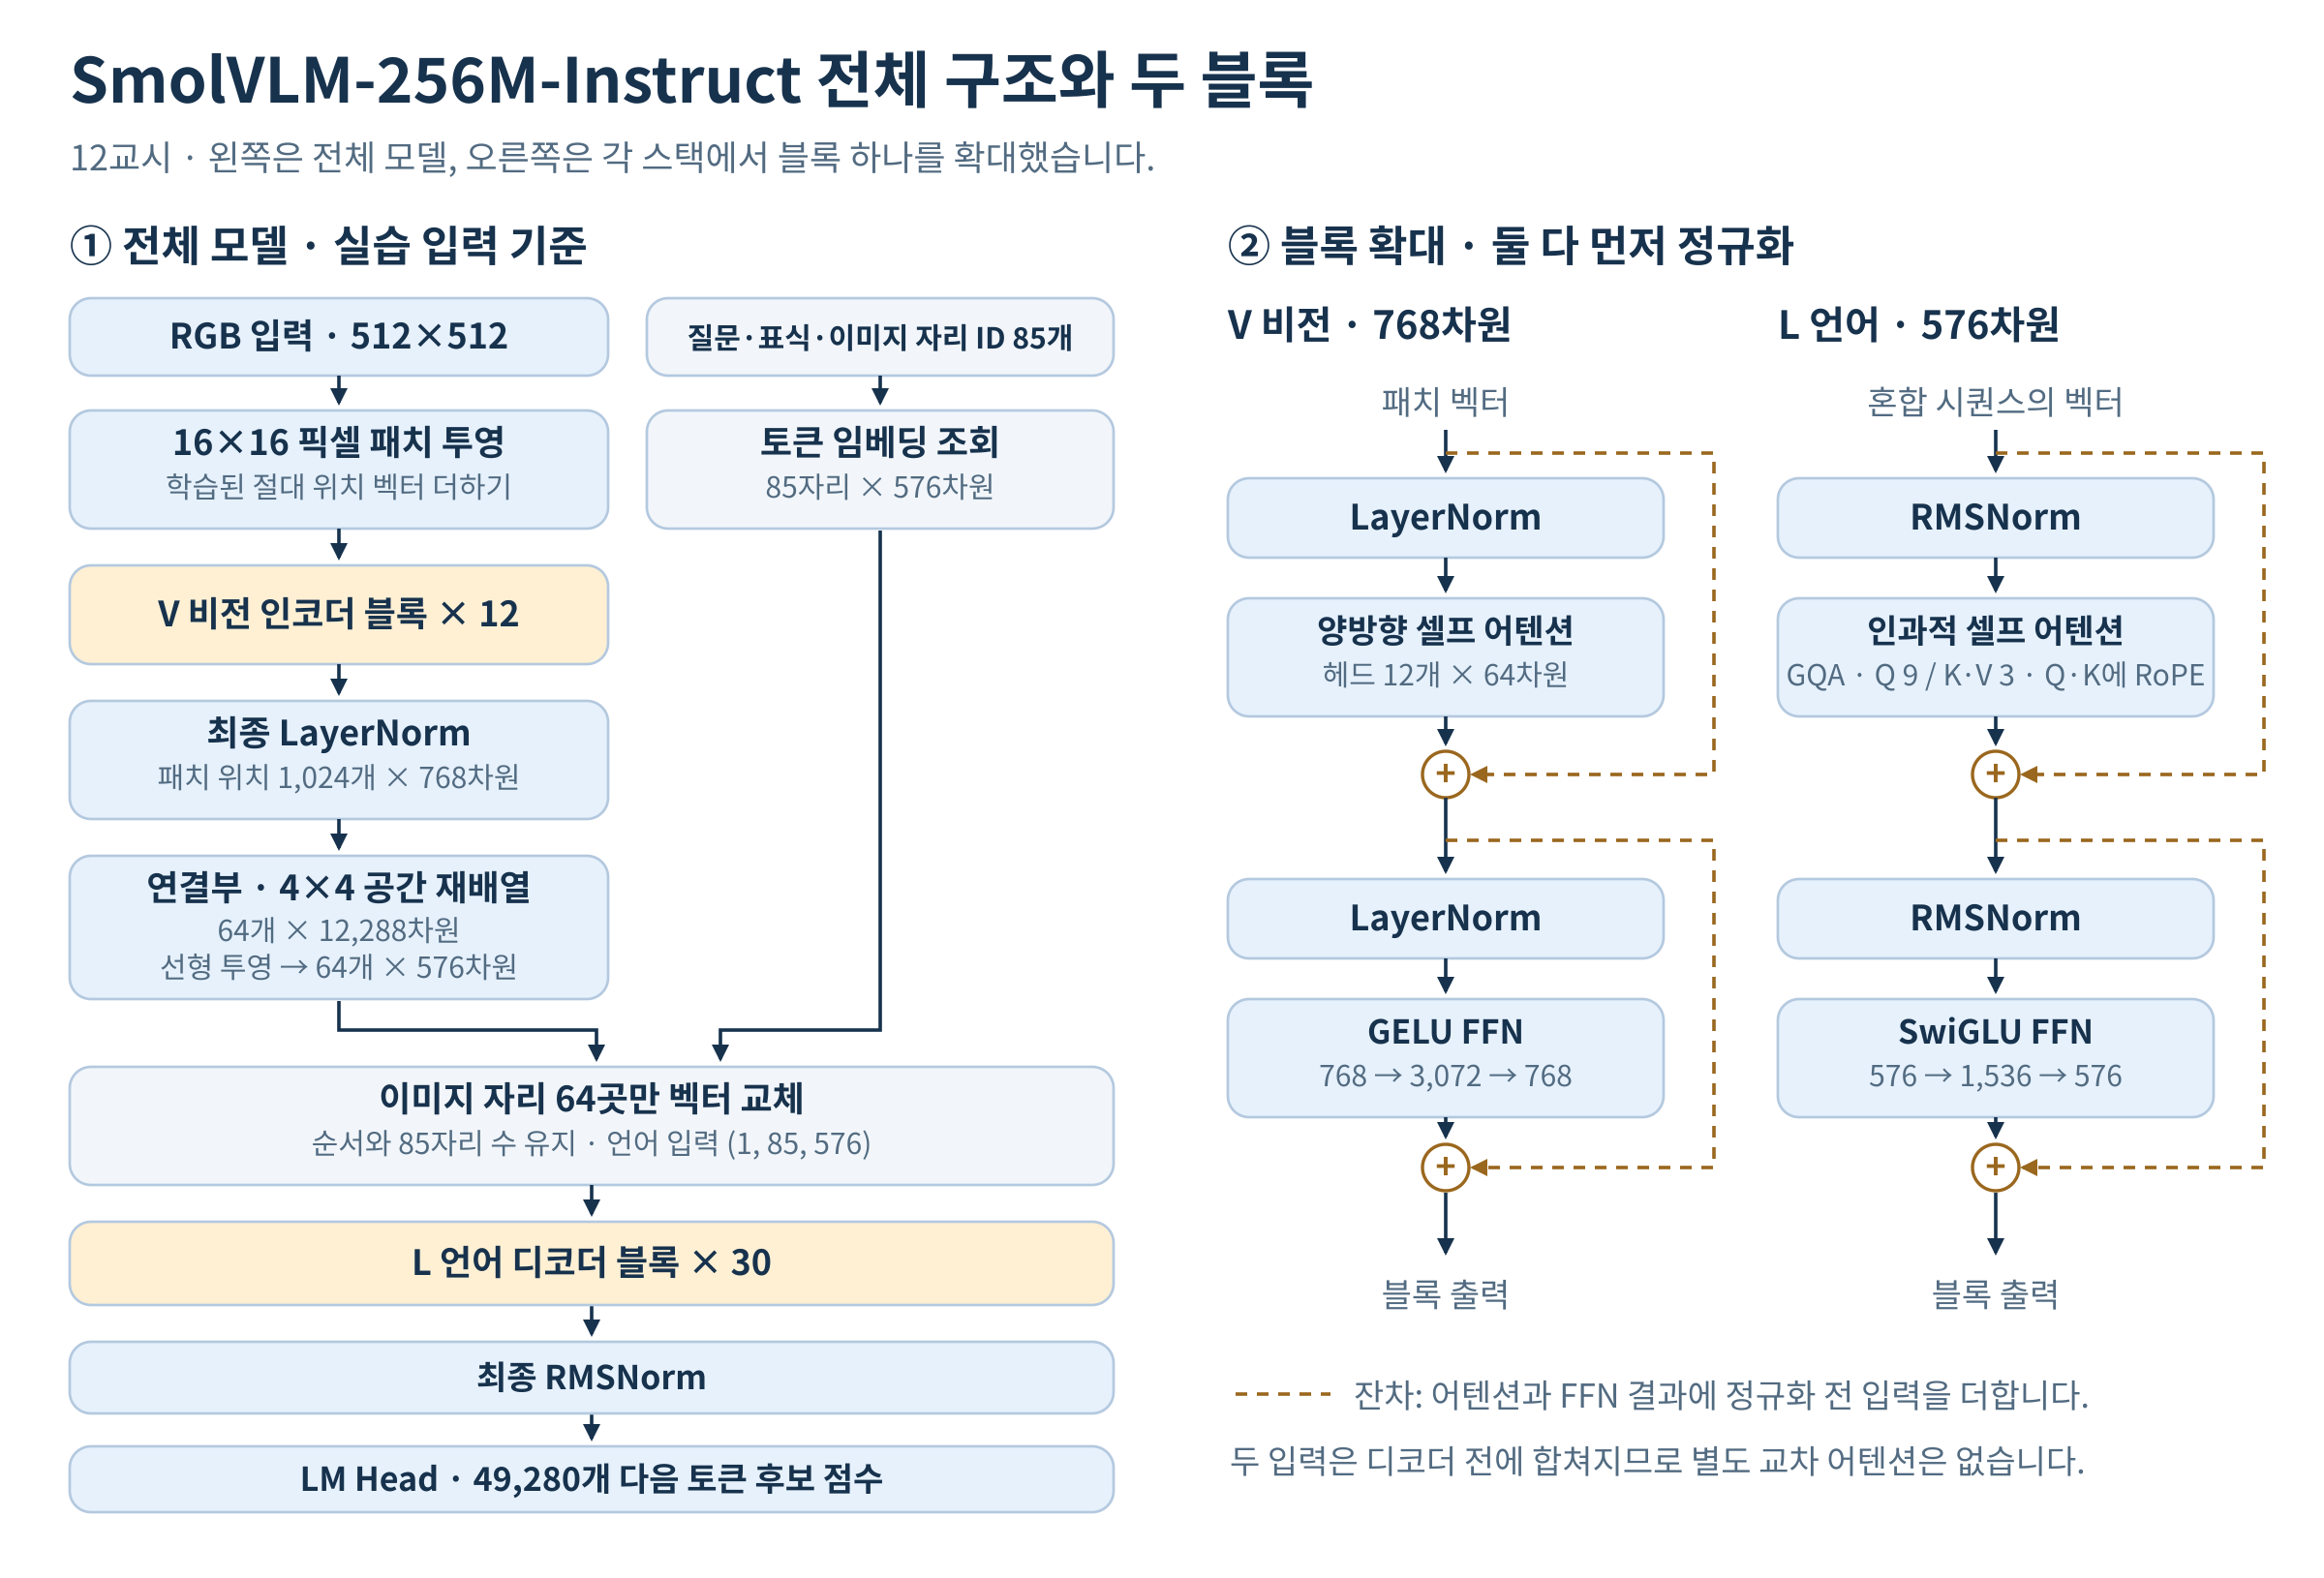

**그림 설명:** 비전 인코더에서는 패치끼리 양방향으로 정보를 참고합니다. 언어 디코더는 이미지 벡터와 질문이 한 줄로 합쳐진 입력에 인과적 셀프 어텐션을 적용합니다. GPT-2와 같이 다음 토큰을 예측하지만, 이 모델은 이미지 벡터도 처음부터 같은 입력에 포함합니다. 별도의 인코더·디코더 간 크로스 어텐션은 쓰지 않습니다.


### 코드 설명: 모델과 처리 규약을 같은 버전에 맞추기

`MODEL_ID`와 `REVISION`으로 가중치, 토크나이저, `processor_config.json`, `chat_template.json`을 같은 공개 버전에서 불러옵니다. PIL 입력 처리기의 `do_image_splitting=False`는 고해상도 분할 대신 전체 그림 한 장만 지나가게 합니다. `image_seq_len`은 이 처리 규약에서 이 실습에서 처리한 이미지 뷰 한 장에 배정하는 언어 입력 자리 수입니다.

모델은 학습된 비전 인코더·연결부·언어 모델을 함께 불러옵니다. `.to(DEVICE).eval()`로 장치를 맞추고 평가 모드로 전환합니다. 이때 관찰할 내부 모듈의 참조가 `core`이고, 실제 입력의 중간값은 §5에서 읽습니다. FP32와 PyTorch SDPA를 사용하며, SDPA 지정 자체가 특정 FlashAttention 커널 실행을 뜻하지는 않습니다.


In [3]:
from transformers import AutoTokenizer, Idefics3Processor, Idefics3ForConditionalGeneration
from transformers.models.idefics3.image_processing_pil_idefics3 import Idefics3ImageProcessorPil
from huggingface_hub import hf_hub_download
MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
REVISION = "d039ab0d4b9311b617e8ffec1d06c8464364aeb3"
# PIL backend를 명시해 torchvision 추가 설치 없이 공식 전처리를 사용합니다.
# 분할하지 않는 한 장 입력을 관찰하기 위해 아래에서 두 크기를 512로 고정합니다.
image_processor = Idefics3ImageProcessorPil.from_pretrained(
    MODEL_ID, revision=REVISION, token=False,
    do_image_splitting=False, size={"longest_edge": 512}, max_image_size={"longest_edge": 512}
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, token=False)
# 이 체크포인트의 원래 processor 설정에서 chat template와 토큰 길이를 읽습니다.
processor_config_path = hf_hub_download(MODEL_ID, "processor_config.json", revision=REVISION, token=False)
# 다운로드 함수의 반환값은 경로이므로 파일을 읽어 JSON 설정을 꺼냅니다.
processor_config = json.loads(Path(processor_config_path).read_text(encoding="utf-8"))
chat_template_path = hf_hub_download(MODEL_ID, "chat_template.json", revision=REVISION, token=False)
chat_template = json.loads(Path(chat_template_path).read_text(encoding="utf-8"))["chat_template"]
# 이미지 처리기·토크나이저에 체크포인트의 이미지 길이와 채팅 템플릿을 결합합니다.
processor = Idefics3Processor(
    image_processor=image_processor, tokenizer=tokenizer,
    image_seq_len=processor_config["image_seq_len"], chat_template=chat_template
)
# SmolVLM 체크포인트를 구현 클래스 Idefics3로 읽으며 별도 모델 둘을 로드하지 않습니다.
model = Idefics3ForConditionalGeneration.from_pretrained(
    MODEL_ID, revision=REVISION, token=False, use_safetensors=True,
    dtype=DTYPE, attn_implementation="sdpa"
).to(DEVICE).eval()
# 시각 encoder와 언어 모델을 연결하는 내부 모듈을 관찰하기 위한 참조입니다.
# 생성용 바깥 모델 안에서 시각 연결층과 텍스트 모델을 찾아 hook을 붙일 참조입니다.
core = model.model
assert model.config.model_type == "idefics3"
# 공간 묶음 크기와 두 벡터 폭이 이후 1024→64 토큰 경로의 조건과 맞는지 검사합니다.
assert model.config.scale_factor == 4
assert model.config.vision_config.hidden_size == 768
assert model.config.text_config.hidden_size == 576
assert processor.image_seq_len == 64
print("parameters:", sum(p.numel() for p in model.parameters()))
print("vision dimension:", model.config.vision_config.hidden_size)
print("language dimension:", model.config.text_config.hidden_size)
print("image_seq_len:", processor.image_seq_len)
print("[PASS] actual pretrained SmolVLM checkpoint loaded")

W1117 22:12:11.417000 9472 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights:  31%|███       | 147/471 [00:00<00:00, 1464.68it/s]

Loading weights:  62%|██████▏   | 294/471 [00:00<00:00, 1337.85it/s]

Loading weights:  91%|█████████ | 429/471 [00:00<00:00, 1154.15it/s]

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 1214.88it/s]

parameters: 256484928
vision dimension: 768
language dimension: 576
image_seq_len: 64
[PASS] actual pretrained SmolVLM checkpoint loaded


### 출력 설명

모델의 파라미터는 256,484,928개입니다. **768과 576은 벡터 하나의 폭**입니다. 768은 시각 벡터, 576은 언어 입력 벡터의 폭입니다. 64는 폭이 아니라 **이 뷰 한 장이 채울 이미지 자리 수**입니다.


## 4. 픽셀과 이미지 자리표시자는 어떻게 다를까요?

### 개념 먼저

영화관의 예약 표시가 관객을 대신하지 않듯, 이미지 자리표시자 ID는 이미지 벡터를 넣을 위치만 알려 줍니다. 그림의 픽셀은 `pixel_values`에, 질문과 자리표시자 ID는 `input_ids`에 따로 들어갑니다. **이 단계에서는 아직 시각 벡터를 계산하지 않았습니다.**

**같은 그림이라도 질문은 바꿀 수 있습니다.** 예를 들어 “무슨 모양이 있나요?”와 “무슨 색이 있나요?”는 그림 쪽 픽셀 입력은 같지만 질문 쪽 토큰 ID가 달라집니다. 따라서 두 질문의 전체 토큰 수가 같을 필요는 없습니다. 이는 설명용 비교이며, 실습 코드는 색과 모양을 함께 묻는 질문 한 개만 실행합니다.


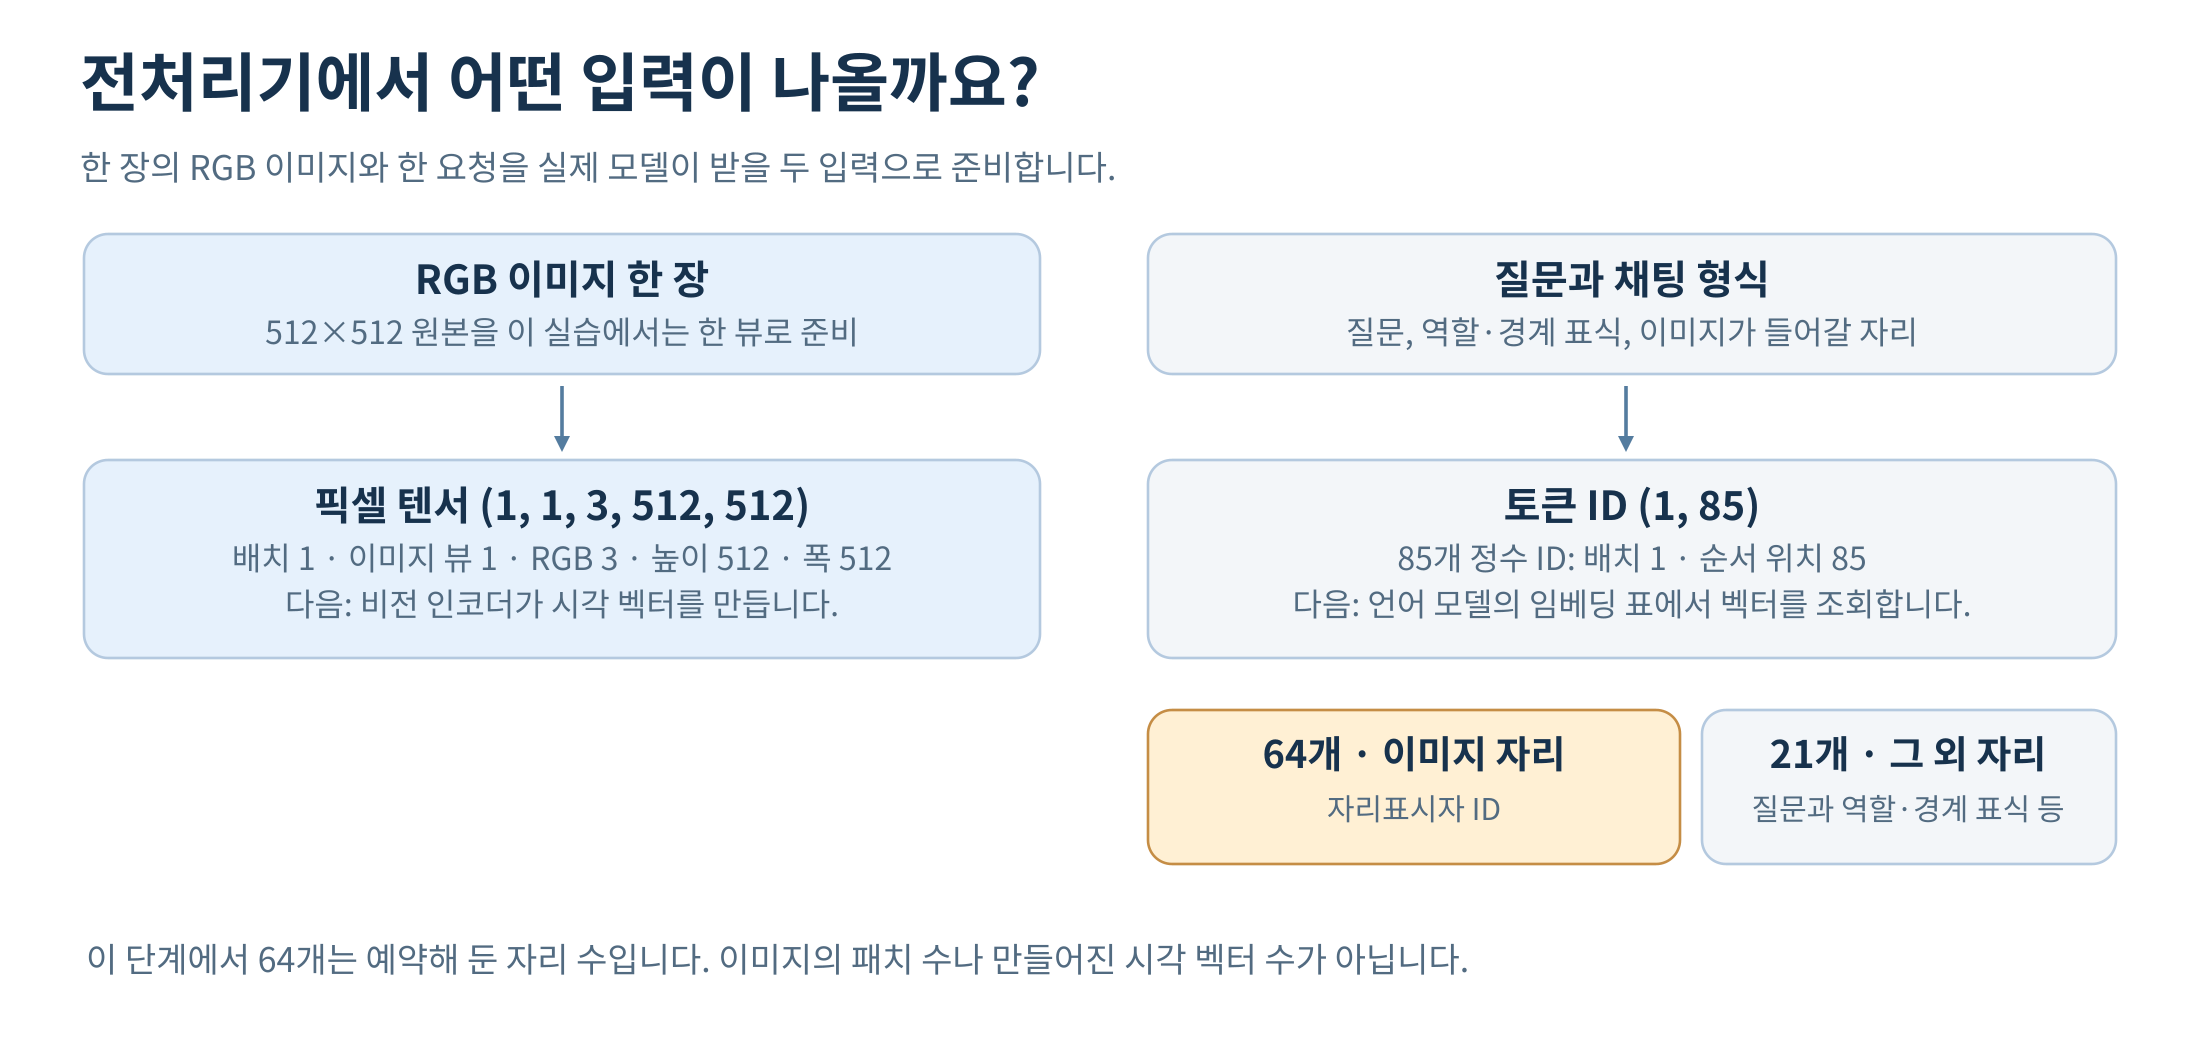

**그림 설명:** 픽셀에는 그림의 색 정보가 있지만, 이미지 자리표시자 ID에는 색 정보가 없습니다. ID는 나중에 시각 벡터를 넣을 위치를 알려 줍니다.

**이 실습에서 이미지 자리는 어디에 있을까요?** 코드는 사용자 메시지 안에 이미지를 먼저, 질문을 그다음에 넣습니다. 대화 형식과 전처리를 적용한 입력 순서를 단순화하면 다음과 같습니다.

사용자 역할 표식 → 이미지 시작 표식 등 → `<image>` 64개 → 이미지 끝 표식 → 질문 문장 → 답변 시작 표식

즉, 이미지 자리는 질문보다 앞이지만 전체 입력의 맨 앞은 아닙니다. 위 그림에서 64개와 21개로 나눈 것은 **종류별 개수**입니다. 나머지 21곳의 토큰은 이미지 자리 앞뒤에 있고, 아래 실행 출력은 자리의 개수만 보여 줍니다.


### 코드 설명: 질문 ID와 픽셀 값 따로 만들기

`processor`에 원본 이미지와 채팅 형식의 질문을 함께 줍니다. `image_mask`는 전체 ID에서 이미지 자리표시자 ID와 같은 위치를 골라냅니다. 이 마스크는 픽셀을 자르지 않으며, §6에서 해당 자리의 벡터를 꺼내는 데 씁니다.


In [4]:
messages = [{"role": "user", "content": [
    {"type": "image"},
    {"type": "text", "text": "Describe the colors and shapes in this image briefly."}
]}]
# 이미지 위치와 질문을 모델의 채팅 형식 문자열로 만들고 아래 processor가 실제 텐서를 생성합니다.
prompt = processor.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
# 여기까지는 CPU 텐서입니다. 다음 단계에서 모델과 같은 장치로 옮깁니다.
batch_cpu = processor(text=prompt, images=[image], return_tensors="pt")
# 픽셀 등 실수 텐서만 DTYPE으로 바꾸고 토큰 ID의 정수 자료형은 보존합니다.
batch = {k: v.to(DEVICE, dtype=DTYPE) if v.is_floating_point() else v.to(DEVICE)
         for k, v in batch_cpu.items() if isinstance(v, torch.Tensor)}
# 이 모델의 텍스트 경로에 불필요한 processor 보조 출력은 전달하지 않습니다.
batch = {k: v for k, v in batch.items() if k in ("input_ids", "attention_mask", "pixel_values", "pixel_attention_mask")}
# 픽셀 값이 아니라 이미지 벡터를 넣을 언어 시퀀스 위치를 찾습니다.
image_mask = batch["input_ids"] == model.config.image_token_id
# 참·거짓 위치 표를 합산하여 이미지 벡터를 삽입할 자리 수를 셉니다.
image_slots = int(image_mask.sum().item())
# 축은 배치·이미지·채널·높이·너비 순서입니다. 이미지 축 1은 이번 무분할 설정을 반영합니다.
assert tuple(batch["pixel_values"].shape) == (1, 1, 3, 512, 512)
assert image_slots == 64
print("pixel_values:", tuple(batch["pixel_values"].shape))
print("input_ids:", tuple(batch["input_ids"].shape))
print("image placeholder count:", image_slots)
print("vision patch count:", (512 // 16) ** 2)
print("[PASS] one image / no splitting / 64 image positions")

pixel_values: (1, 1, 3, 512, 512)
input_ids: (1, 85)
image placeholder count: 64
vision patch count: 1024
[PASS] one image / no splitting / 64 image positions


### 출력 설명

- `pixel_values: (1, 1, 3, 512, 512)`: 요청 1개, 이미지 뷰 1장, RGB 3채널, 높이·너비 512입니다.
- `input_ids: (1, 85)`: 입력 위치는 모두 85곳입니다. `image placeholder count: 64`는 그중 `<image>` 자리표시자 수입니다. 나머지 21곳에는 위 그림처럼 질문 문장뿐 아니라 대화 형식과 이미지 경계를 표시하는 토큰도 포함됩니다.
- `vision patch count: 1024`: 픽셀 크기로 계산한 패치 위치 32×32개입니다. 다음 절에서 실제 인코더 출력과 대조합니다. **이미지 자리 64개는 이 뷰 한 장의 설정값**이며, 다른 입력 크기나 분할 조건에서 그대로 적용하지 않습니다.


## 5. 연결부를 지나면 시각 벡터는 어떻게 달라질까요?

### 개념 먼저

512÷16=32이므로 이미지 한 변에 16픽셀짜리 패치가 32개 있습니다. 인코더는 32×32 패치에서 특징을 계산해 **1,024개 × 768차원**을 내놓습니다. 이때부터 다루는 것은 RGB 픽셀이 아니라 시각 벡터입니다.

1. **재배열:** 연결부가 이웃 4×4칸의 벡터 16개를 한 묶음으로 모읍니다. 공간상 8×8=64묶음, 묶음 하나의 폭은 16×768=12,288입니다. 원소를 재배치할 뿐 평균을 내거나 64개만 선택하고 나머지를 버리지 않습니다.
2. **투영:** 학습된 선형층이 묶음마다 폭을 12,288에서 576으로 줄입니다. 64개라는 묶음 수는 유지하고 질문 벡터와 폭을 맞춥니다. 재배열 전후의 원소 개수가 같다는 사실이, 폭을 줄인 뒤에도 모든 시각 세부 정보가 그대로 남는다는 뜻은 아닙니다.


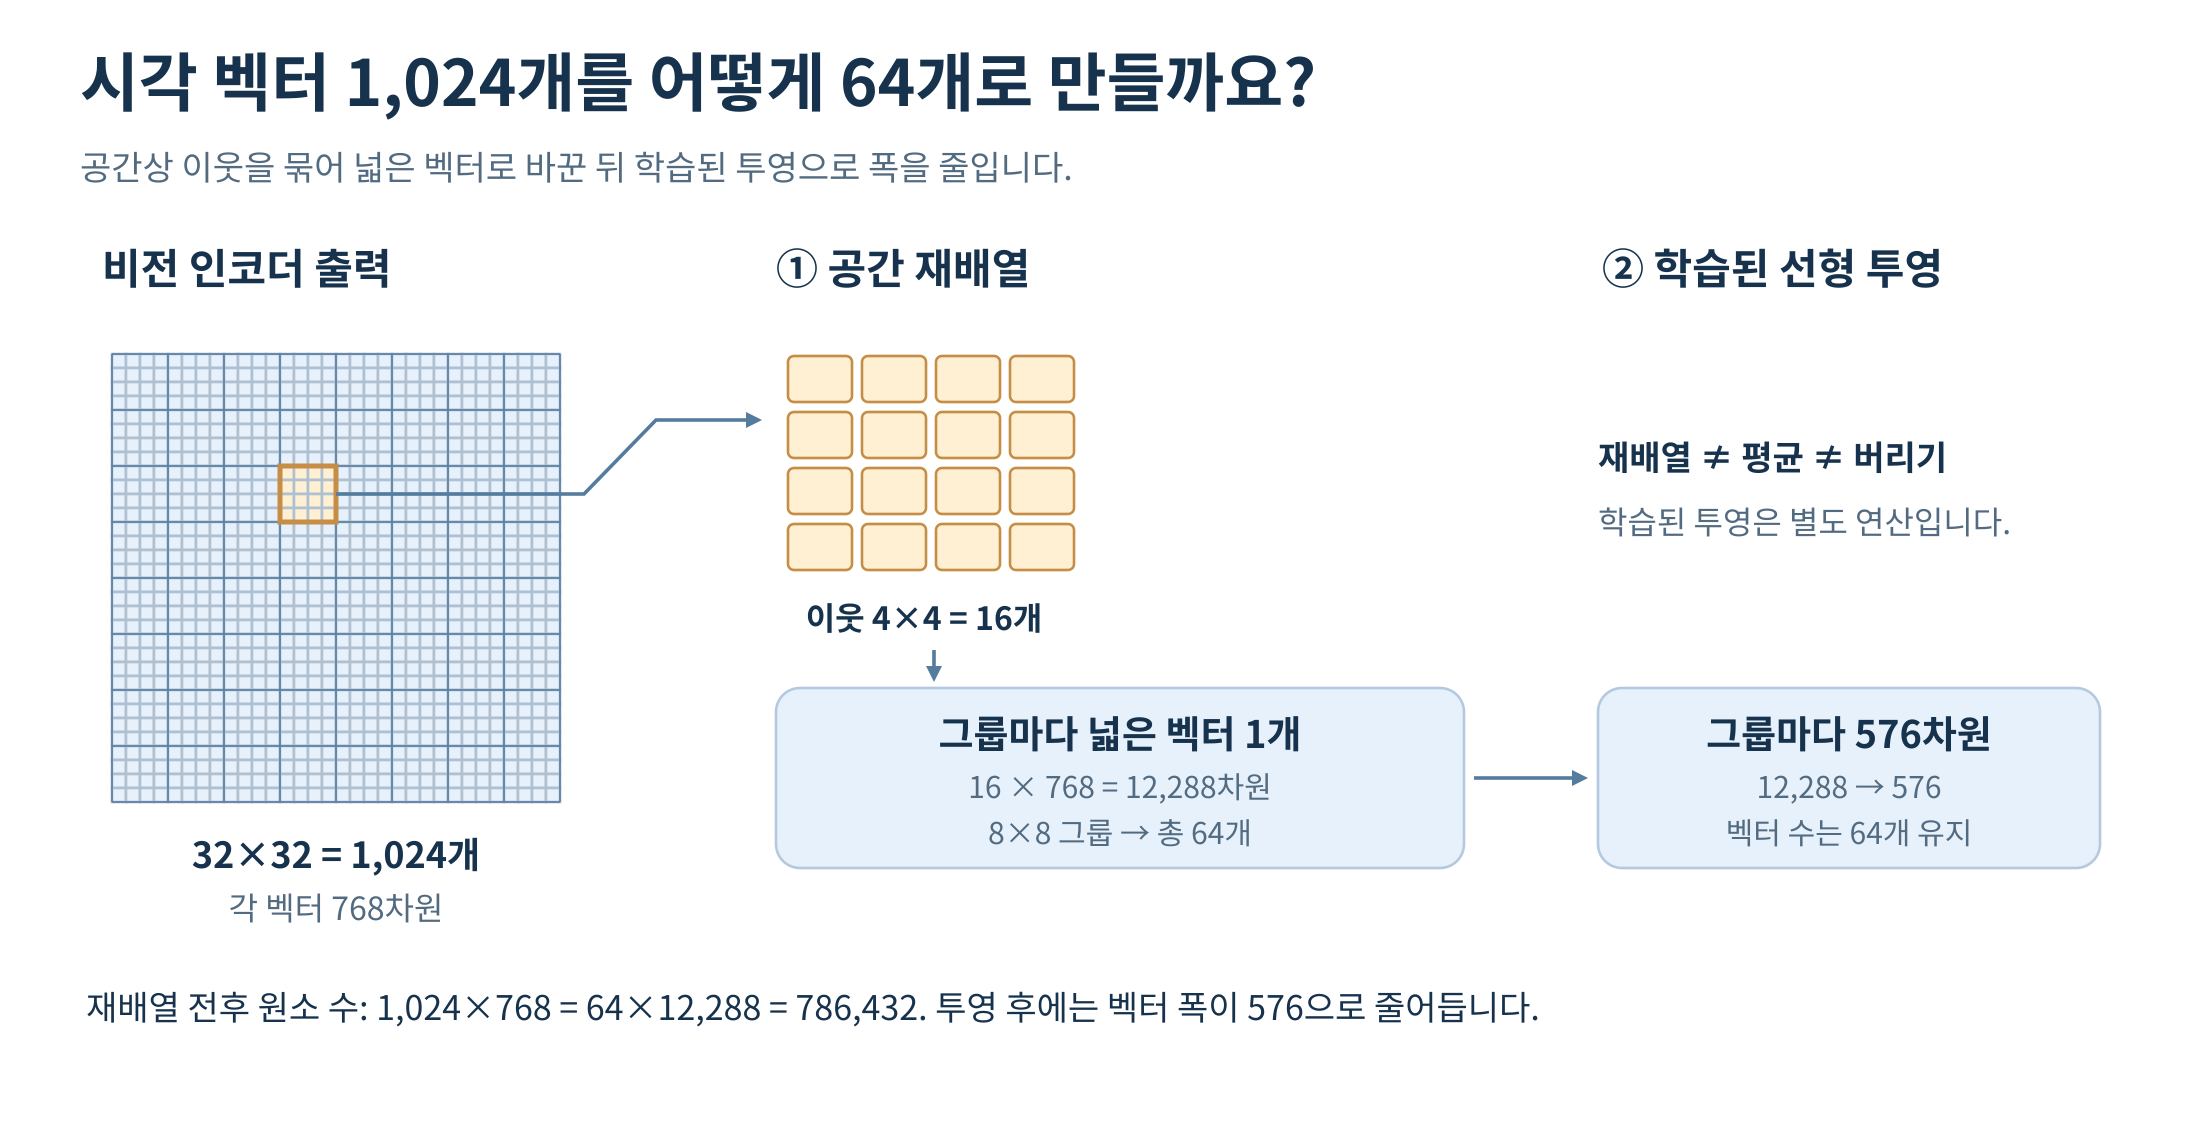

**그림 설명:** 공간 재배열은 4×4개의 벡터를 한 벡터에 모아 원소 수를 유지합니다. 그다음 학습된 선형 투영이 벡터 64개의 폭만 12,288에서 576으로 바꿉니다.


### 코드 설명: 한 번의 순전파에서 중간값 읽기

순전파 훅(hook)은 중간값을 바꾸지 않고 읽기 위한 장치입니다. 연결부 입출력에서 `vision`과 `projected`, 투영층 입구에서 `shuffled`, 언어 모델 입구에서 `lm_inputs`를 수집합니다. 관찰이 끝나면 훅을 제거합니다.


In [5]:
observed = {}
def observe_connector(module, args, output):
    # connector의 첫 입력과 출력을 CPU에 복사해 같은 순전파의 값을 보관합니다.
    observed["vision"] = args[0].detach().cpu()
    observed["projected"] = output.detach().cpu()
def observe_projection(module, args, output):
    # 투영층의 첫 입력을 읽어 공간 재배열 이후의 넓어진 벡터를 관찰합니다.
    observed["shuffled"] = args[0].detach().cpu()
def observe_lm(module, args, kwargs):
    # 실행 전 hook에서 언어 모델에 들어갈 inputs_embeds를 읽습니다.
    observed["lm_inputs"] = kwargs["inputs_embeds"].detach().cpu()
# hook은 값을 읽기만 하고 모델 입출력을 수정하지 않습니다.
# 중간 텐서를 읽는 hook은 관찰 후 제거하여 다음 생성에 남기지 않습니다.
# 등록 핸들을 보관해야 계산 종료 후 같은 관찰 함수를 정확히 제거할 수 있습니다.
handles = [
    core.connector.register_forward_hook(observe_connector),
    core.connector.modality_projection.register_forward_hook(observe_projection),
    core.text_model.register_forward_pre_hook(observe_lm, with_kwargs=True),
]
torch.cuda.reset_peak_memory_stats()
try:
    with torch.inference_mode():
        # 생성 없이 첫 입력 전체를 한 번 처리합니다. 캐시·전체 attention은 저장하지 않습니다.
        output = model(**batch, use_cache=False, return_dict=True)
# 순전파 중 오류가 나도 hook을 제거하여 다음 생성에 관찰 함수가 남지 않게 합니다.
finally:
    for handle in handles:
        handle.remove()
# 네 관찰 지점이 모두 실행된 뒤 shape와 유한값을 각각 검사합니다.
assert set(observed) == {"vision", "shuffled", "projected", "lm_inputs"}
assert tuple(observed["vision"].shape) == (1, 1024, 768)
# 4×4개를 묶어 1024개 위치가 64개로 줄고 폭은 768×16=12288이 됩니다.
assert tuple(observed["shuffled"].shape) == (1, 64, 12288)
assert tuple(observed["projected"].shape) == (1, 64, 576)
for name, value in observed.items():
    assert torch.isfinite(value).all(), name + " contains nonfinite values"
    print(name + ":", tuple(value.shape))
assert torch.isfinite(output.logits).all()
print("[PASS] 1024x768 -> 64x12288 -> 64x576 -> LM")

shuffled: (1, 64, 12288)
vision: (1, 1024, 768)
projected: (1, 64, 576)
lm_inputs: (1, 85, 576)
[PASS] 1024x768 -> 64x12288 -> 64x576 -> LM


### 출력 설명

벡터가 이동하는 순서로 읽습니다.

| 관찰값 | 이 실행의 모양 | 의미 |
| --- | --- | --- |
| `vision` | `(1, 1024, 768)` | 인코더에서 나온 패치별 특징 |
| `shuffled` | `(1, 64, 12288)` | 이웃 16개의 원소를 모은 64묶음 |
| `projected` | `(1, 64, 576)` | 언어 모델과 같은 폭으로 바꾼 64개 벡터 |
| `lm_inputs` | `(1, 85, 576)` | 이미지 벡터가 들어간 연속 64자리와 앞뒤의 나머지 21자리로 이루어진 언어 입력 |

투영층의 훅이 연결부 전체의 훅보다 먼저 끝나므로 실제 출력에서 `shuffled`가 `vision`보다 먼저 인쇄됩니다. PASS는 네 텐서의 모양을 검사한 결과입니다.


## 6. 시각 벡터가 이미지 자리에 실제로 들어갔을까요?

### 개념 먼저

같은 크기의 텐서라도 값은 다를 수 있습니다. [Idefics3의 병합 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/idefics3/modeling_idefics3.py)이 올바른 값을 전달했는지 다음 두 가지를 비교합니다.

1. **이미지 자리 64곳:** 언어 입력에서 꺼낸 값이 같은 순전파의 연결부 출력과 맞는지 봅니다.
2. **나머지 21곳:** 원래 토큰 ID로 언어 모델의 임베딩 표를 조회한 값과 맞는지 봅니다.

바뀌는 것은 ID 자체가 아니라 **언어 모델에 넘기는 임베딩**입니다. 시각 특징을 전달하는 방법이 모든 VLM에서 같은 것은 아니며, 이 실습은 SmolVLM의 경로를 확인합니다.


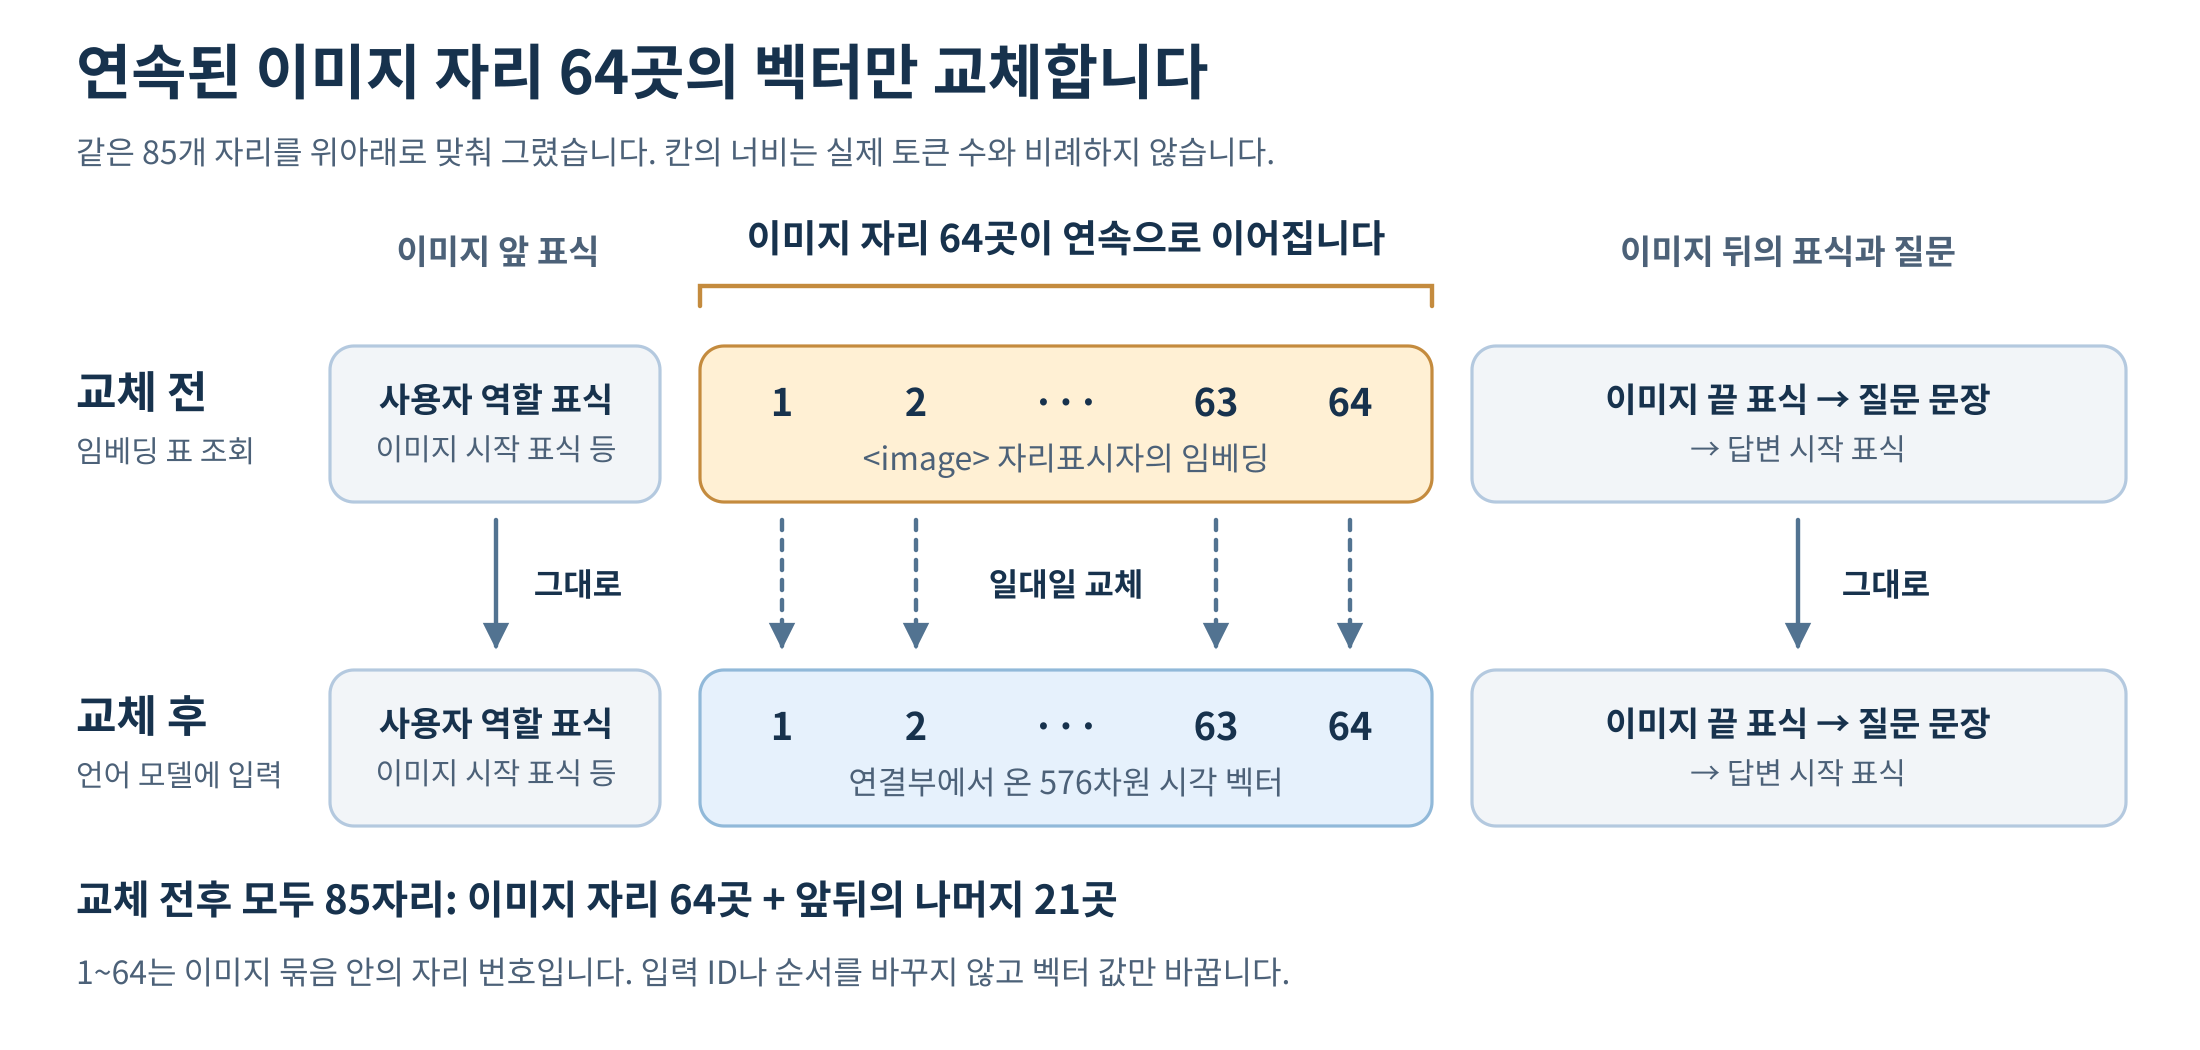

**그림 설명:** 이 입력에서 이미지 시작과 끝 표식 사이의 자리 64곳은 연속입니다. 각 자리를 연결부의 시각 벡터 하나로 교체하고, 앞뒤의 역할·경계 표식과 질문 등 나머지 21곳의 임베딩은 그대로 둡니다. 교체 전후 길이는 모두 85이며, 입력 ID나 순서는 바뀌지 않습니다.


### 코드 설명: 두 종류의 위치를 따로 대조하기

`assert_close`는 원소마다 기준값 `b`와의 절대차가 `0.000001 + 0.00001 × |b|` 이내인지 확인합니다. `atol=1e-6`은 기준값이 0이어도 적용하는 절대 허용오차이고, `rtol=1e-5`는 기준값의 크기에 비례해 더하는 상대 허용오차입니다. 이미지 자리는 연결부 출력, 나머지 자리는 원래 토큰 임베딩을 기준으로 삼습니다. 별도의 `numel()` 검사는 재배열 전후의 원소 개수가 같은지 확인합니다.


In [6]:
# 동일한 forward에서 관찰한 connector 출력과 LM 입력의 이미지 위치가 같은지 확인합니다.
image_positions_cpu = image_mask.cpu()
# 불리언 마스크로 이미지 자리만 뽑으면 배치 축이 합쳐진 (64,576)이 됩니다.
inserted = observed["lm_inputs"][image_positions_cpu]
# 같은 순전파의 connector 출력과 실제 삽입 벡터를 값 수준에서 대조합니다.
# connector 출력도 (64,576)로 맞춰 같은 위치의 실제 벡터 값을 비교합니다.
expected = observed["projected"].reshape(-1, 576)
# 형태뿐 아니라 원소별 수치도 절대·상대 허용 오차 내에서 일치하는지 확인합니다.
# 기준은 연결층 출력 expected이며 원소별로 0.000001+0.00001×|expected|를 허용합니다.
torch.testing.assert_close(inserted, expected, rtol=1e-5, atol=1e-6)
# 이미지가 아닌 위치는 원래 텍스트 임베딩을 그대로 사용합니다.
with torch.inference_mode():
    # 입력 토큰 ID로 실제 임베딩 표를 조회해 시각 벡터 삽입 전 텍스트 값을 복원합니다.
    original_text_embeddings = core.text_model.get_input_embeddings()(batch["input_ids"]).detach().cpu()
# ~마스크는 이미지가 아닌 위치입니다. 그 자리의 텍스트 임베딩이 바뀌지 않았는지 검사합니다.
# 텍스트 위치는 원래 임베딩이 기준이며 같은 atol=1e-6, rtol=1e-5로 비교합니다.
torch.testing.assert_close(observed["lm_inputs"][~image_positions_cpu],
                           original_text_embeddings[~image_positions_cpu], rtol=1e-5, atol=1e-6)
# shuffle 전후 원소 수가 같다는 검사이며 학습된 투영까지 정보 보존을 뜻하지 않습니다.
assert observed["vision"].numel() == observed["shuffled"].numel()
print("inserted image vectors:", tuple(inserted.shape))
print("[PASS] image placeholders replaced by projected vision vectors")
print("[PASS] other text positions retain their text embeddings")
print("[PASS] pixel shuffle reorganizes elements; learned projection changes dimension")

inserted image vectors: (64, 576)
[PASS] image placeholders replaced by projected vision vectors
[PASS] other text positions retain their text embeddings
[PASS] pixel shuffle reorganizes elements; learned projection changes dimension


### 출력 설명

`inserted image vectors: (64, 576)`와 세 줄의 PASS를 읽으세요. 이미지 자리에 연결부의 값이 들어갔고, 나머지 임베딩은 유지됐으며, 재배열 전후 원소 수가 같았습니다. **그림의 특징이 전달됐다는 확인이지 답변이 맞다는 보장은 아닙니다.**


## 7. 연결이 맞으면 설명도 맞을까요?

### 개념 먼저

앞 절은 이미지 벡터가 언어 모델에 들어갔는지 확인했습니다. 다음 셀은 생성한 문장을 §2의 그림과 비교하는 별도 단계입니다.


### 코드 설명: 새로 만든 토큰만 읽기

언어 모델은 매 단계에서 점수가 가장 높은 다음 토큰을 고릅니다(그리디, greedy). 새 토큰은 최대 24개로 제한하며, 입력 토큰을 떼고 새로 만든 부분만 문자열로 읽습니다. 원본 그림을 보며 **말한 내용이 맞는지**와 **문장이 끝났는지**를 따로 확인하세요.


In [7]:
# 짧은 실제 생성은 연결 결과를 경험하기 위한 보조 활동입니다.
# 앞 순전파의 큰 logits 참조를 해제해 생성 전에 불필요한 메모리 점유를 줄입니다.
del output
gc.collect()
with torch.inference_mode():
    # greedy 선택으로 최대 24개 새 토큰을 만들며 과거 K/V를 재사용합니다.
    generated = model.generate(**batch, max_new_tokens=24, do_sample=False, num_beams=1, use_cache=True)
# generate 반환값에는 입력도 포함되므로 새로 생성된 부분만 분리합니다.
prompt_length = batch["input_ids"].shape[1]
# generate 결과의 입력 접두부를 제외하여 새로 생성된 부분만 디코딩합니다.
answer_ids = generated[:, prompt_length:]
# 배치의 첫 문자열을 꺼내며 제어 표식을 숨겨 사람이 읽는 설명으로 만듭니다.
answer = tokenizer.batch_decode(answer_ids, skip_special_tokens=True)[0]
print("Generated text:", answer)
print("Generated tokens:", answer_ids.shape[1])
# 새 토큰 생성 여부와 상한 준수만 검사합니다. 이미지 설명의 정답 판정은 아닙니다.
assert 0 < answer_ids.shape[1] <= 24
print("[PASS] generation executed; visual correctness is NOT a PASS condition")

Generated text:  The image is a simple geometric shape consisting of two rectangles. The rectangles are identical in shape and size, with each rectangle
Generated tokens: 24
[PASS] generation executed; visual correctness is NOT a PASS condition


### 출력 설명

저장된 출력에는 `two rectangles`라는 표현이 나옵니다. 원본은 **빨간 사각형 하나와 파란 원 하나**이므로 이미 언급한 모양이 잘못됐습니다. 24토큰 상한에서 문장도 끝나지 않았습니다. 이 셀의 생성 PASS는 토큰이 제한 안에서 만들어졌다는 뜻입니다.


## 8. 결과 기록

무엇을 실행했고 어디까지 검사했는지 결과를 남깁니다.


### 코드 설명: 검사와 생성문을 JSON에 기록하기

`lesson12-result.json`에 모델과 실행 조건, 중간 텐서의 모양, 값 검사 결과, 생성문을 남깁니다. 전체 중간 텐서를 저장하거나 검사를 다시 하는 셀이 아닙니다.


In [8]:
torch.cuda.synchronize()
# 연결 검사 결과와 생성문을 함께 보관하되 시각 정답 검증으로 과장하지 않습니다.
# 앞서 관찰한 shape·검사 판정·생성문을 함께 기록하며 검사를 다시 실행하지 않습니다.
report = {
    "lesson": 12, "status": "PASS", "model_id": MODEL_ID, "revision": REVISION,
    "implementation": type(model).__name__, "torch": torch.__version__,
    "transformers": transformers.__version__, "cuda": torch.version.cuda,
    "device": DEVICE, "dtype": str(DTYPE), "image_splitting": False,
    "pixel_shape": list(batch["pixel_values"].shape), "image_placeholder_count": image_slots,
    # 전체 관찰 텐서 대신 축 크기만 저장하여 JSON 보고서를 가볍게 유지합니다.
    "observed_shapes": {k: list(v.shape) for k, v in observed.items()},
    "image_vectors_match_lm_input": True, "text_positions_unchanged": True,
    # 바로 앞 생성 셀의 토큰 수와 문자열을 기록하며 새로운 생성을 실행하지 않습니다.
    "generated_tokens": int(answer_ids.shape[1]), "generated_text": answer,
    "peak_allocated_mib": round(torch.cuda.max_memory_allocated()/1024**2, 2),
    # 구조 연결 PASS를 시각 정확도 평가 PASS로 오해하지 않도록 명시적으로 구분합니다.
    "visual_accuracy_evaluated": False
}
# 전체 관찰 텐서가 아닌 요약 JSON을 보관합니다. 시각 정답 여부는 별도입니다.
(OUT / "lesson12-result.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(report, ensure_ascii=False, indent=2))

{
  "lesson": 12,
  "status": "PASS",
  "model_id": "HuggingFaceTB/SmolVLM-256M-Instruct",
  "revision": "d039ab0d4b9311b617e8ffec1d06c8464364aeb3",
  "implementation": "Idefics3ForConditionalGeneration",
  "torch": "2.9.1+cu126",
  "transformers": "5.23.0",
  "cuda": "12.6",
  "device": "cuda",
  "dtype": "torch.float32",
  "image_splitting": false,
  "pixel_shape": [
    1,
    1,
    3,
    512,
    512
  ],
  "image_placeholder_count": 64,
  "observed_shapes": {
    "shuffled": [
      1,
      64,
      12288
    ],
    "vision": [
      1,
      1024,
      768
    ],
    "projected": [
      1,
      64,
      576
    ],
    "lm_inputs": [
      1,
      85,
      576
    ]
  },
  "image_vectors_match_lm_input": true,
  "text_positions_unchanged": true,
  "generated_tokens": 24,
  "generated_text": " The image is a simple geometric shape consisting of two rectangles. The rectangles are identical in shape and size, with each rectangle",
  "peak_allocated_mib": 1061.48,
  "visual_

### 출력 설명

`image_vectors_match_lm_input`과 `text_positions_unchanged`는 값 검사 통과를, `visual_accuracy_evaluated: false`는 코드가 별도의 정확도 평가를 하지 않았음을 뜻합니다. 원본 한 장과 답변을 눈으로 비교한 일과 평가 데이터로 일반 정확도를 측정하는 일은 다릅니다.

이 실행의 `peak_allocated_mib`는 1061.48 MiB입니다. §5 순전파 직전부터 결과 기록까지 PyTorch가 추적한 GPU 할당 최고치로, 이미 올라간 가중치도 포함합니다. 장치 전체 사용량이나 최소 VRAM은 아닙니다.


## 문제 해결

**이미지 자리 수가 64와 다르면:** 이미지 분할·resize 설정과 고정 checkpoint revision을 확인합니다. assert를 지워 통과시키지 않습니다.

**import 오류:** 프로젝트 커널과 Transformers 5.23.0을 확인합니다. 기본 torchvision processor 대신 이 Notebook의 명시적 PIL processor를 사용합니다. 임의로 패키지를 설치하지 않습니다.

**CUDA 메모리 오류:** 이전 교시 커널을 종료한 뒤 새 커널에서 처음부터 실행합니다. 이미지 크기·개수·분할 설정을 원래대로 복원하세요. 다른 프로세스를 강제 종료하지 않습니다.

**모델 다운로드 실패:** 공식 공개 모델 접근과 캐시를 확인합니다. 액세스 토큰을 Notebook에 적거나 외부 서비스로 이미지를 보내지 않습니다.


## 정리와 자기 점검

1. **타일 분할을 끄면 패치도 없어지나요?** 아닙니다. 입력 처리기는 512×512 뷰 한 장을 넘기고 비전 인코더는 그 안에서 16×16픽셀 패치를 사용합니다.
2. **1,024, 64, 85는 각각 무엇인가요?** 순서대로 인코더의 패치 위치, 연결부가 만든 이미지 벡터 수, 이 질문의 전체 입력 위치 수입니다.
3. **이미지 연결을 확인한 근거는 무엇인가요?** 같은 순전파에서 꺼낸 이미지 자리의 값이 연결부 출력과 맞았고, 나머지 값은 원래 임베딩과 맞았습니다.
4. **그림을 그대로 두고 질문만 바꾸면 무엇이 달라지나요?** 픽셀 입력은 같지만 질문의 토큰열과 답변은 달라질 수 있습니다. 이 실습에서는 한 질문만 실행했습니다.
5. **연결과 생성이 PASS이면 정답인가요?** 아닙니다. 연결·생성 여부와 답변의 시각 정확성·완료 여부를 각각 확인해야 합니다.


## 참고 자료

- [SmolVLM-256M 공식 모델 카드](https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct)
- [고정 checkpoint config](https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct/blob/d039ab0d4b9311b617e8ffec1d06c8464364aeb3/config.json)
- [Transformers 5.23.0 Idefics3 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/idefics3/modeling_idefics3.py): connector·pixel shuffle·inputs_merger·언어 모델 호출
- [공식 SmolVLM 기술 보고서](https://arxiv.org/abs/2504.05299)
